# SECOM — Leakage-Controlled SHAP Feature Selection for Rare-Failure Detection

## Goal
Test whether selecting the top SHAP-ranked transformed features improves failure detection compared with using all features that survive the project's existing statistical selector. The primary selection objective is **F2**, which weights failure recall more heavily than precision, while PR-AUC, precision, false alarms, and missed failures remain visible.

### Experiment
- Dataset: official UCI SECOM (1,567 rows; 590 original sensors; 104 failures).
- Final test split: stratified 20%, kept untouched during cross-validation and model/threshold selection.
- Existing filter pipeline: constant-feature removal, >50% missingness filtering, Mann–Whitney U, Benjamini–Hochberg FDR, effect-size filtering, and Spearman redundancy pruning.
- SHAP ranking: compute positive-class mean absolute SHAP **inside each CV training fold**, using an Extra Trees ranker; then train candidate classifiers on Top 10/20/30/50 or all eligible transformed features.
- Classifiers: Extra Trees, Random Forest, and class-weighted Logistic Regression.
- Thresholds: tuned from training-set out-of-fold probabilities only. The untouched test set is evaluated only for the single selected configuration.

**Important:** these experiments test whether SHAP-based feature selection helps. They do not assume it will improve recall, and selected sensors are predictive signals rather than proven physical causes.

## Existing SHAP results from the earlier project notebook

The earlier robust Extra Trees notebook did compute `mean_abs_shap = abs(shap_values_positive).mean(axis=0)`. The previously recorded report included this top-ranked subset:

| Previous rank | Transformed feature | Previous mean absolute SHAP |
|---:|---|---:|
| 1 | Sensor_104 | 0.016184 |
| 2 | missingindicator_Sensor_346 | 0.014954 |
| 3 | missingindicator_Sensor_347 | 0.012973 |
| 4 | Sensor_60 | 0.012699 |
| 5 | Sensor_500 | 0.011854 |
| 6 | Sensor_512 | 0.011791 |
| 7 | Sensor_130 | 0.011141 |
| 8 | Sensor_511 | 0.010193 |
| 9 | Sensor_125 | 0.009775 |
| 10 | Sensor_424 | 0.009301 |
| 11 | Sensor_122 | 0.009237 |
| 12 | Sensor_15 | 0.009114 |

**Leakage caution:** the earlier SHAP ranking was computed over the old held-out test rows. Therefore, this notebook keeps those values only as a historical reference and does **not** use them to select features for the new CV/test evaluation. Instead, it recomputes rankings from each training fold. This is the fair way to estimate whether SHAP-based selection generalizes.

In [1]:
# Install only the missing explainability dependency. In Colab, run this cell first.
%pip -q install shap

In [2]:
import io
import zipfile
import urllib.request
import warnings
import random

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import shap

from scipy.stats import mannwhitneyu
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import RobustScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier
from sklearn.metrics import (
    balanced_accuracy_score, roc_auc_score, average_precision_score,
    precision_score, recall_score, f1_score, fbeta_score,
    confusion_matrix, precision_recall_curve
)

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)
random.seed(SEED)

print("SHAP version:", shap.__version__)
print("Imports successful.")

SHAP version: 0.54.1
Imports successful.


In [3]:
# Historical SHAP values from the previous project report (reference only).
# They are NOT used for training or choosing the new feature subset.
legacy_shap_reference = pd.DataFrame([
    ("Sensor_104", 0.016184),
    ("missingindicator_Sensor_346", 0.014954),
    ("missingindicator_Sensor_347", 0.012973),
    ("Sensor_60", 0.012699),
    ("Sensor_500", 0.011854),
    ("Sensor_512", 0.011791),
    ("Sensor_130", 0.011141),
    ("Sensor_511", 0.010193),
    ("Sensor_125", 0.009775),
    ("Sensor_424", 0.009301),
    ("Sensor_122", 0.009237),
    ("Sensor_15", 0.009114),
], columns=["feature", "legacy_mean_abs_shap"])
display(legacy_shap_reference)

,feature,legacy_mean_abs_shap
0,Sensor_104,0.016184
1,missingindicator_Sensor_346,0.014954
2,missingindicator_Sensor_347,0.012973
3,Sensor_60,0.012699
4,Sensor_500,0.011854
5,Sensor_512,0.011791
6,Sensor_130,0.011141
7,Sensor_511,0.010193
8,Sensor_125,0.009775
9,Sensor_424,0.009301


In [4]:
# Load the official UCI SECOM dataset.
UCI_URL = "https://archive.ics.uci.edu/static/public/179/secom.zip"

def load_secom():
    with urllib.request.urlopen(UCI_URL, timeout=60) as response:
        raw = response.read()
    with zipfile.ZipFile(io.BytesIO(raw)) as archive:
        names = archive.namelist()
        def locate(filename):
            hits = [name for name in names if name.lower().endswith(filename.lower())]
            if not hits:
                raise FileNotFoundError(f"{filename} was not found in the UCI archive.")
            return hits[0]
        with archive.open(locate("secom.data")) as f:
            X = pd.read_csv(f, sep=r"\s+", header=None, engine="python")
        with archive.open(locate("secom_labels.data")) as f:
            labels = pd.read_csv(
                f, sep=r"\s+", header=None,
                names=["label", "date", "time"], engine="python"
            )
    if len(X) != len(labels):
        raise ValueError(f"Feature/label row mismatch: {len(X)} vs {len(labels)}")
    X.columns = [f"Sensor_{i+1}" for i in range(X.shape[1])]
    X = X.replace([np.inf, -np.inf], np.nan)
    y = (labels["label"].astype(int) == 1).astype(int)
    assert X.shape == (1567, 590), f"Unexpected data shape: {X.shape}"
    assert int(y.sum()) == 104, f"Expected 104 failures, got {int(y.sum())}"
    return X, y

X, y = load_secom()
print("Data shape:", X.shape)
print("Failures:", int(y.sum()), f"({y.mean():.2%})")
print("Passes:", int((y == 0).sum()))

Data shape: (1567, 590)
Failures: 104 (6.64%)
Passes: 1463


## 1. Preserve the project's existing statistical filter

This feature selector is fitted anew within each CV training fold. It does not inspect the corresponding validation fold or the final test set while deciding which raw sensor columns to retain.

In [5]:
class StatisticalFeatureSelector(BaseEstimator, TransformerMixin):
    """Training-fold-only filter selector based on the earlier SECOM notebook."""
    def __init__(self, missing_threshold=0.50, fdr_alpha=0.05,
                 min_effect=0.15, max_features=80,
                 corr_threshold=0.90, min_features=10):
        self.missing_threshold = missing_threshold
        self.fdr_alpha = fdr_alpha
        self.min_effect = min_effect
        self.max_features = max_features
        self.corr_threshold = corr_threshold
        self.min_features = min_features

    @staticmethod
    def bh_adjust(p):
        p = np.asarray(p, dtype=float)
        n = len(p)
        order = np.argsort(p)
        ranked = p[order]
        q = ranked * n / np.arange(1, n + 1)
        q = np.minimum.accumulate(q[::-1])[::-1]
        q = np.clip(q, 0, 1)
        out = np.empty(n)
        out[order] = q
        return out

    @staticmethod
    def rank_auc(a, b):
        n0, n1 = len(a), len(b)
        if n0 == 0 or n1 == 0:
            return 0.5
        values = np.concatenate([a, b])
        ranks = pd.Series(values).rank(method="average").to_numpy()
        u = ranks[n0:].sum() - n1 * (n1 + 1) / 2
        auc = u / (n0 * n1)
        return float(max(auc, 1 - auc))

    def fit(self, X, y):
        X = pd.DataFrame(X).copy().reset_index(drop=True)
        y = pd.Series(np.asarray(y)).reset_index(drop=True)
        self.feature_names_in_ = np.asarray(X.columns, dtype=object)

        nonconstant = X.nunique(dropna=True) > 1
        candidates = X.columns[nonconstant].tolist()
        candidates = [c for c in candidates if X[c].isna().mean() <= self.missing_threshold]
        if not candidates:
            raise ValueError("No features survived quality filtering.")

        Xi = X[candidates].replace([np.inf, -np.inf], np.nan)
        Xi = Xi.fillna(Xi.median()).fillna(0)
        neg = y.to_numpy() == 0
        pos = y.to_numpy() == 1
        rows = []
        for feature in candidates:
            a = Xi.loc[neg, feature].to_numpy()
            b = Xi.loc[pos, feature].to_numpy()
            try:
                _, p_value = mannwhitneyu(a, b, alternative="two-sided")
                auc = self.rank_auc(a, b)
            except Exception:
                p_value, auc = 1.0, 0.5
            scale = np.nanstd(Xi[feature].to_numpy(), ddof=1)
            effect = (abs(np.nanmedian(b) - np.nanmedian(a)) / scale
                      if np.isfinite(scale) and scale > 1e-12 else 0.0)
            rows.append((feature, p_value, effect, auc))

        stats = pd.DataFrame(rows, columns=["feature", "p_value", "effect", "auc"])
        stats["q_value"] = self.bh_adjust(stats["p_value"])
        stats["auc_distance"] = (stats["auc"] - 0.5).abs()
        selected = stats[(stats["q_value"] <= self.fdr_alpha) &
                         (stats["effect"] >= self.min_effect)].copy()
        if len(selected) < self.min_features:
            selected = stats.sort_values(
                ["q_value", "auc_distance", "effect"],
                ascending=[True, False, False]
            ).head(min(self.max_features, len(stats)))
        selected = selected.sort_values(
            ["q_value", "auc_distance", "effect"],
            ascending=[True, False, False]
        ).head(self.max_features)
        names = selected["feature"].tolist()

        if len(names) > 1:
            corr = Xi[names].corr(method="spearman").abs()
            kept = []
            for feature in names:
                if all(corr.loc[feature, previous] < self.corr_threshold for previous in kept):
                    kept.append(feature)
            names = kept
        if not names:
            names = [stats.sort_values("q_value").iloc[0]["feature"]]

        self.selected_features_ = names
        self.statistics_ = stats.sort_values("q_value").reset_index(drop=True)
        return self

    def transform(self, X):
        X = pd.DataFrame(X).copy()
        missing = [c for c in self.selected_features_ if c not in X.columns]
        if missing:
            raise ValueError(f"Missing selected features: {missing[:5]}")
        return X[self.selected_features_].copy()

    def get_feature_names_out(self, input_features=None):
        return np.asarray(self.selected_features_, dtype=object)

print("Statistical selector ready.")

Statistical selector ready.


## 2. Define fold-specific preprocessing and SHAP ranking

For each fold, the steps are: fit statistical selector → impute and add missingness indicators → train an Extra Trees ranker → rank transformed features by positive-class mean absolute SHAP → evaluate models trained on each subset. The validation fold is never used for the SHAP ranking.

In [6]:
FEATURE_COUNTS = [10, 20, 30, 50]
SUBSET_LABELS = [f"Top {k} SHAP" for k in FEATURE_COUNTS] + ["All eligible"]
MODEL_NAMES = ["Extra Trees", "Random Forest", "Logistic Regression"]
N_SPLITS = 5
SHAP_RANK_SAMPLE = 700  # SHAP on a reproducible sample of each training fold to reduce runtime.


def make_extra_trees(seed=SEED):
    return ExtraTreesClassifier(
        n_estimators=350, min_samples_leaf=2, max_features="sqrt",
        class_weight="balanced", n_jobs=-1, random_state=seed
    )


def make_candidate_model(name, seed=SEED):
    if name == "Extra Trees":
        return make_extra_trees(seed)
    if name == "Random Forest":
        return RandomForestClassifier(
            n_estimators=350, min_samples_leaf=2, max_features="sqrt",
            class_weight="balanced_subsample", n_jobs=-1, random_state=seed
        )
    if name == "Logistic Regression":
        from sklearn.pipeline import Pipeline as SklearnPipeline
        return SklearnPipeline([
            ("scaler", RobustScaler()),
            ("model", LogisticRegression(
                max_iter=3000, class_weight="balanced", C=0.5,
                solver="liblinear", random_state=seed
            ))
        ])
    raise ValueError(f"Unknown model: {name}")


def positive_class_shap_values(raw_values, n_samples, n_features):
    """Normalize SHAP's version-dependent binary-class output to (samples, features)."""
    if isinstance(raw_values, list):
        if len(raw_values) < 2:
            values = np.asarray(raw_values[0])
        else:
            values = np.asarray(raw_values[1])
    else:
        values = np.asarray(raw_values)
        if values.ndim == 3:
            if values.shape[0] == n_samples and values.shape[1] == n_features:
                values = values[:, :, 1]  # (samples, features, classes)
            elif values.shape[0] == 2 and values.shape[1] == n_samples:
                values = values[1, :, :]  # (classes, samples, features)
            elif values.shape[0] == n_samples and values.shape[2] == n_features:
                values = values[:, 1, :]  # less common (samples, classes, features)
            else:
                raise ValueError(f"Unrecognized 3-D SHAP shape: {values.shape}")
    if values.ndim != 2 or values.shape != (n_samples, n_features):
        raise ValueError(
            f"Expected SHAP matrix {(n_samples, n_features)}, got {values.shape}"
        )
    return values


def fit_preprocessor(X_fit, y_fit, X_valid):
    selector = StatisticalFeatureSelector(
        missing_threshold=0.50, fdr_alpha=0.05, min_effect=0.15,
        max_features=80, corr_threshold=0.90, min_features=10
    )
    X_fit_selected = selector.fit_transform(X_fit, y_fit)
    X_valid_selected = selector.transform(X_valid)
    imputer = SimpleImputer(strategy="median", add_indicator=True)
    fit_array = imputer.fit_transform(X_fit_selected)
    valid_array = imputer.transform(X_valid_selected)
    names = imputer.get_feature_names_out(selector.selected_features_)
    X_fit_ready = pd.DataFrame(fit_array, columns=names, index=X_fit.index)
    X_valid_ready = pd.DataFrame(valid_array, columns=names, index=X_valid.index)
    return selector, imputer, X_fit_ready, X_valid_ready


def calculate_shap_rankings(rank_model, X_fit_ready, fold_seed):
    # Sample from training-fold inputs only; does not touch validation or final test rows.
    if len(X_fit_ready) > SHAP_RANK_SAMPLE:
        X_shap = X_fit_ready.sample(n=SHAP_RANK_SAMPLE, random_state=fold_seed)
    else:
        X_shap = X_fit_ready
    explainer = shap.TreeExplainer(rank_model)
    raw_values = explainer.shap_values(X_shap)
    values = positive_class_shap_values(
        raw_values, n_samples=len(X_shap), n_features=X_shap.shape[1]
    )
    return (pd.DataFrame({
        "feature": X_fit_ready.columns,
        "mean_abs_shap": np.abs(values).mean(axis=0)
    }).sort_values("mean_abs_shap", ascending=False).reset_index(drop=True))

print("Feature subsets:", SUBSET_LABELS)
print("Candidate models:", MODEL_NAMES)

Feature subsets: ['Top 10 SHAP', 'Top 20 SHAP', 'Top 30 SHAP', 'Top 50 SHAP', 'All eligible']
Candidate models: ['Extra Trees', 'Random Forest', 'Logistic Regression']


## 3. Cross-validated SHAP feature-subset experiment

Each row receives an out-of-fold probability from a model that did not train on that row. SHAP ranks are rebuilt separately inside every fold. The five feature subsets are therefore evaluated as a **feature-selection procedure**, rather than with one fixed ranking calculated from the final test set.

In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED
)
# Normalize indexes so OOF assignment and transformed rows remain easy to track.
X_train = X_train.reset_index(drop=True)
X_test = X_test.reset_index(drop=True)
y_train = y_train.reset_index(drop=True)
y_test = y_test.reset_index(drop=True)

print("Development train:", X_train.shape, "failures:", int(y_train.sum()))
print("Untouched final test:", X_test.shape, "failures:", int(y_test.sum()))

Development train: (1253, 590) failures: 83
Untouched final test: (314, 590) failures: 21


In [8]:
cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
config_keys = [(model_name, subset_label)
               for model_name in MODEL_NAMES for subset_label in SUBSET_LABELS]
oof_probabilities = {key: np.full(len(X_train), np.nan) for key in config_keys}
fold_shap_tables = []
fold_subset_counts = []

for fold_no, (fit_idx, valid_idx) in enumerate(cv.split(X_train, y_train), start=1):
    print(f"\nFold {fold_no}/{N_SPLITS}")
    X_fit, X_valid = X_train.iloc[fit_idx], X_train.iloc[valid_idx]
    y_fit, y_valid = y_train.iloc[fit_idx], y_train.iloc[valid_idx]

    selector, imputer, X_fit_ready, X_valid_ready = fit_preprocessor(X_fit, y_fit, X_valid)
    rank_model = make_extra_trees(seed=SEED + fold_no)
    rank_model.fit(X_fit_ready, y_fit)
    fold_shap = calculate_shap_rankings(rank_model, X_fit_ready, fold_seed=SEED + fold_no)
    fold_shap["fold"] = fold_no
    fold_shap_tables.append(fold_shap)

    ranked = fold_shap["feature"].tolist()
    print("Raw candidate sensors after statistical filtering:", len(selector.selected_features_))
    print("Transformed features including missingness indicators:", X_fit_ready.shape[1])
    print("Top five fold-specific SHAP features:", ranked[:5])

    for subset_label in SUBSET_LABELS:
        if subset_label == "All eligible":
            chosen = ranked
        else:
            k = int(subset_label.split()[1])
            chosen = ranked[:min(k, len(ranked))]
        fold_subset_counts.append({
            "fold": fold_no, "subset": subset_label, "n_features": len(chosen)
        })

        X_fit_subset = X_fit_ready[chosen]
        X_valid_subset = X_valid_ready[chosen]
        for model_name in MODEL_NAMES:
            model = make_candidate_model(model_name, seed=SEED + fold_no)
            model.fit(X_fit_subset, y_fit)
            probability = model.predict_proba(X_valid_subset)[:, 1]
            oof_probabilities[(model_name, subset_label)][valid_idx] = probability

assert all(np.isfinite(p).all() for p in oof_probabilities.values()), "Some OOF predictions are missing."
fold_shap_long = pd.concat(fold_shap_tables, ignore_index=True)
fold_subset_counts = pd.DataFrame(fold_subset_counts)
print("\nCross-validation completed.")


Fold 1/5
Raw candidate sensors after statistical filtering: 58
Transformed features including missingness indicators: 110
Top five fold-specific SHAP features: ['Sensor_489', 'Sensor_60', 'Sensor_104', 'Sensor_512', 'Sensor_125']

Fold 2/5
Raw candidate sensors after statistical filtering: 58
Transformed features including missingness indicators: 104
Top five fold-specific SHAP features: ['missingindicator_Sensor_347', 'Sensor_500', 'Sensor_65', 'Sensor_512', 'Sensor_60']

Fold 3/5
Raw candidate sensors after statistical filtering: 55
Transformed features including missingness indicators: 105
Top five fold-specific SHAP features: ['Sensor_104', 'Sensor_60', 'missingindicator_Sensor_347', 'missingindicator_Sensor_248', 'missingindicator_Sensor_73']

Fold 4/5
Raw candidate sensors after statistical filtering: 51
Transformed features including missingness indicators: 97
Top five fold-specific SHAP features: ['Sensor_500', 'Sensor_434', 'Sensor_104', 'Sensor_66', 'Sensor_125']

Fold 5/5
R

## 4. Tune decision thresholds from OOF training predictions

Recall can be increased by lowering the threshold, but this can sharply increase false alarms. We use **F2** to choose a threshold because it weights recall more strongly than precision, then report recall, precision, PR-AUC, balanced accuracy, and counts of false alarms/missed failures. This is a configurable research choice—not a universal industrial operating point.

In [9]:
def metrics_at_threshold(y_true, probability, threshold, model_name="model", subset="subset"):
    y_true = np.asarray(y_true, dtype=int)
    probability = np.asarray(probability, dtype=float)
    prediction = (probability >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_true, prediction, labels=[0, 1]).ravel()
    return {
        "model": model_name,
        "feature_subset": subset,
        "threshold": float(threshold),
        "balanced_accuracy": balanced_accuracy_score(y_true, prediction),
        "roc_auc": roc_auc_score(y_true, probability),
        "pr_auc_average_precision": average_precision_score(y_true, probability),
        "recall": recall_score(y_true, prediction, zero_division=0),
        "precision": precision_score(y_true, prediction, zero_division=0),
        "f1": f1_score(y_true, prediction, zero_division=0),
        "f2": fbeta_score(y_true, prediction, beta=2, zero_division=0),
        "TN": int(tn), "FP_false_alarms": int(fp),
        "FN_missed_failures": int(fn), "TP": int(tp)
    }


def choose_threshold_for_f2(y_true, probability):
    candidates = np.unique(np.r_[
        np.linspace(0.01, 0.99, 99),
        np.quantile(probability, np.linspace(0, 1, 51))
    ])
    rows = []
    for threshold in candidates:
        pred = (probability >= threshold).astype(int)
        rows.append({
            "threshold": float(threshold),
            "f2": fbeta_score(y_true, pred, beta=2, zero_division=0),
            "recall": recall_score(y_true, pred, zero_division=0),
            "precision": precision_score(y_true, pred, zero_division=0),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred)
        })
    table = pd.DataFrame(rows).sort_values(
        ["f2", "recall", "precision", "balanced_accuracy"],
        ascending=[False, False, False, False]
    ).reset_index(drop=True)
    return float(table.iloc[0]["threshold"]), table


oof_summary_rows = []
threshold_tables = {}
selected_thresholds = {}
for model_name, subset_label in config_keys:
    key = (model_name, subset_label)
    probability = oof_probabilities[key]
    threshold, threshold_table = choose_threshold_for_f2(y_train, probability)
    selected_thresholds[key] = threshold
    threshold_tables[key] = threshold_table
    oof_summary_rows.append(metrics_at_threshold(
        y_train, probability, threshold,
        model_name=model_name, subset=subset_label
    ))

oof_summary = pd.DataFrame(oof_summary_rows).sort_values(
    ["f2", "recall", "pr_auc_average_precision", "precision"],
    ascending=[False, False, False, False]
).reset_index(drop=True)

display(oof_summary[[
    "model", "feature_subset", "threshold", "balanced_accuracy", "roc_auc",
    "pr_auc_average_precision", "recall", "precision", "f1", "f2",
    "FP_false_alarms", "FN_missed_failures"
]].round(4))
print("\nInterpret PR-AUC as ranking quality; recall/precision and false-alarm counts depend on the selected threshold.")

,model,feature_subset,threshold,balanced_accuracy,roc_auc,pr_auc_average_precision,recall,precision,f1,f2,FP_false_alarms,FN_missed_failures
0,Extra Trees,Top 50 SHAP,0.1363,0.6617,0.7086,0.1700,0.5422,0.1495,0.2344,0.3555,256,38
1,Random Forest,Top 50 SHAP,0.0800,0.6621,0.7044,0.1454,0.6506,0.1239,0.2081,0.3516,382,29
2,Extra Trees,All eligible,0.1189,0.6514,0.7025,0.1588,0.6627,0.1155,0.1968,0.3403,421,28
3,Random Forest,All eligible,0.1119,0.6466,0.6954,0.1490,0.4940,0.1486,0.2284,0.3372,235,42
4,Random Forest,Top 30 SHAP,0.0524,0.6472,0.6773,0.1484,0.7952,0.1012,0.1796,0.3354,586,17
5,Extra Trees,Top 20 SHAP,0.0903,0.6407,0.6752,0.1410,0.7831,0.0997,0.1769,0.3303,587,18
6,Extra Trees,Top 30 SHAP,0.1400,0.6407,0.6642,0.1492,0.5422,0.1286,0.2079,0.3299,305,38
7,Random Forest,Top 20 SHAP,0.0900,0.6336,0.6633,0.1315,0.5663,0.1184,0.1958,0.3224,350,36
8,Logistic Regression,Top 50 SHAP,0.3200,0.6325,0.6346,0.1199,0.6265,0.1095,0.1864,0.3222,423,31
9,Logistic Regression,All eligible,0.4400,0.6292,0.6287,0.1114,0.5301,0.1215,0.1978,0.3170,318,39



Interpret PR-AUC as ranking quality; recall/precision and false-alarm counts depend on the selected threshold.


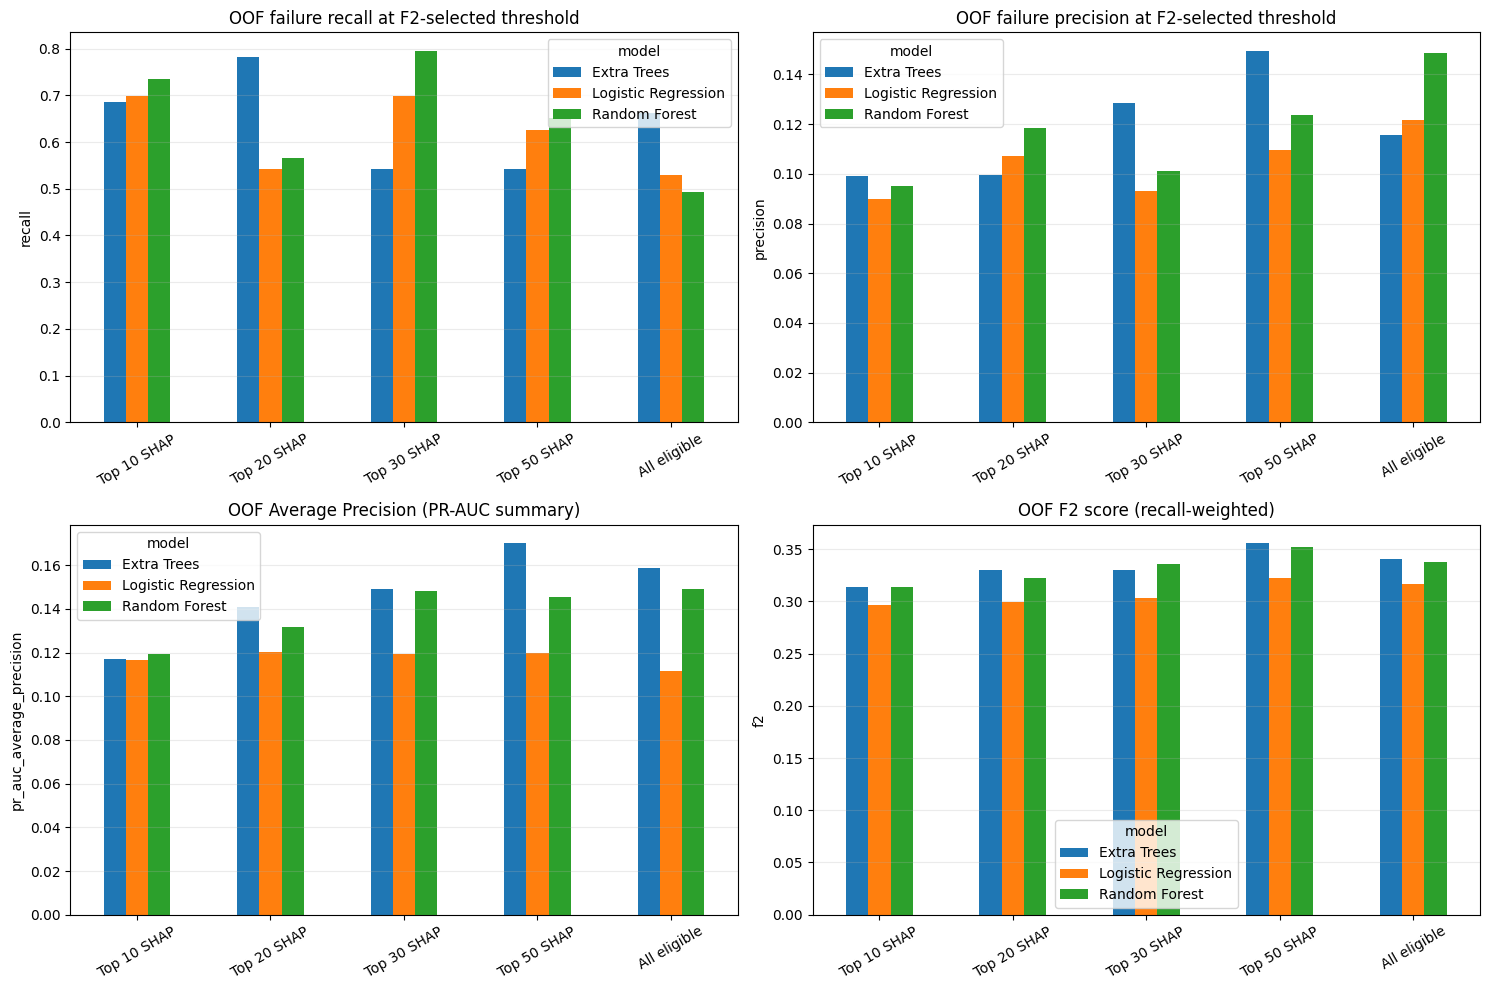

In [10]:
# Visual comparison: OOF recall, precision, PR-AUC and F2 for each model/subset.
fig, axes = plt.subplots(2, 2, figsize=(15, 10))
plot_metrics = [
    ("recall", "OOF failure recall at F2-selected threshold"),
    ("precision", "OOF failure precision at F2-selected threshold"),
    ("pr_auc_average_precision", "OOF Average Precision (PR-AUC summary)"),
    ("f2", "OOF F2 score (recall-weighted)")
]
for ax, (metric, title) in zip(axes.flat, plot_metrics):
    pivot = oof_summary.pivot(index="feature_subset", columns="model", values=metric)
    pivot = pivot.reindex(SUBSET_LABELS)
    pivot.plot(kind="bar", ax=ax)
    ax.set_title(title)
    ax.set_xlabel("")
    ax.set_ylabel(metric)
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.25)
plt.tight_layout()
plt.show()

## 5. Select one configuration using training-only CV results

The configuration with the highest OOF F2 is chosen; ties are resolved by recall, Average Precision, and precision. Because many configurations are compared, their winning CV score is a selection score—not a final unbiased performance estimate. The untouched test set below is used once for the chosen configuration only.

In [11]:
best_row = oof_summary.iloc[0]
best_model_name = str(best_row["model"])
best_subset_label = str(best_row["feature_subset"])
best_threshold = float(best_row["threshold"])

print("Selected model:", best_model_name)
print("Selected feature subset:", best_subset_label)
print(f"Training-OOF threshold: {best_threshold:.4f}")
print(f"Training-OOF recall: {best_row['recall']:.3f}")
print(f"Training-OOF precision: {best_row['precision']:.3f}")
print(f"Training-OOF F2: {best_row['f2']:.3f}")
print(f"Training-OOF Average Precision: {best_row['pr_auc_average_precision']:.3f}")

Selected model: Extra Trees
Selected feature subset: Top 50 SHAP
Training-OOF threshold: 0.1363
Training-OOF recall: 0.542
Training-OOF precision: 0.150
Training-OOF F2: 0.355
Training-OOF Average Precision: 0.170


## 6. Fit the selected configuration and evaluate the untouched test set once

For the final ranking, we fit the statistical filter, imputer, and Extra Trees SHAP ranker using **training data only**. We then select the chosen number of features, fit the selected classifier, and evaluate the test set at the already-selected OOF threshold. Test labels are not used to select features or thresholds.

In [12]:
# Fit final preprocessing on development training data only.
final_selector = StatisticalFeatureSelector(
    missing_threshold=0.50, fdr_alpha=0.05, min_effect=0.15,
    max_features=80, corr_threshold=0.90, min_features=10
)
X_train_selected = final_selector.fit_transform(X_train, y_train)
X_test_selected = final_selector.transform(X_test)
final_imputer = SimpleImputer(strategy="median", add_indicator=True)
X_train_array = final_imputer.fit_transform(X_train_selected)
X_test_array = final_imputer.transform(X_test_selected)
final_feature_names = final_imputer.get_feature_names_out(final_selector.selected_features_)
X_train_ready = pd.DataFrame(X_train_array, columns=final_feature_names, index=X_train.index)
X_test_ready = pd.DataFrame(X_test_array, columns=final_feature_names, index=X_test.index)

# Rank features from TRAINING rows only.
final_ranker = make_extra_trees(seed=SEED)
final_ranker.fit(X_train_ready, y_train)
final_shap_importance = calculate_shap_rankings(final_ranker, X_train_ready, fold_seed=SEED)

if best_subset_label == "All eligible":
    final_selected_features = final_shap_importance["feature"].tolist()
else:
    final_k = min(int(best_subset_label.split()[1]), len(final_shap_importance))
    final_selected_features = final_shap_importance["feature"].head(final_k).tolist()

print("Raw sensors selected by statistical filter:", len(final_selector.selected_features_))
print("Transformed features available for SHAP selection:", len(final_shap_importance))
print("Final features used:", len(final_selected_features))
print("Selected transformed features:", final_selected_features)

display(final_shap_importance.head(25))

Raw sensors selected by statistical filter: 56
Transformed features available for SHAP selection: 109
Final features used: 50
Selected transformed features: ['Sensor_104', 'missingindicator_Sensor_346', 'missingindicator_Sensor_347', 'Sensor_60', 'Sensor_512', 'Sensor_500', 'Sensor_130', 'Sensor_511', 'Sensor_125', 'Sensor_15', 'Sensor_131', 'Sensor_122', 'Sensor_424', 'Sensor_478', 'Sensor_123', 'Sensor_588', 'Sensor_317', 'Sensor_184', 'Sensor_96', 'Sensor_101', 'Sensor_176', 'Sensor_64', 'missingindicator_Sensor_113', 'Sensor_126', 'Sensor_22', 'Sensor_71', 'missingindicator_Sensor_248', 'Sensor_82', 'Sensor_103', 'Sensor_11', 'Sensor_461', 'Sensor_418', 'Sensor_181', 'Sensor_79', 'Sensor_41', 'Sensor_127', 'Sensor_282', 'Sensor_29', 'Sensor_57', 'Sensor_153', 'Sensor_349', 'Sensor_80', 'Sensor_337', 'Sensor_366', 'Sensor_378', 'Sensor_470', 'Sensor_352', 'Sensor_248', 'Sensor_334', 'Sensor_432']


,feature,mean_abs_shap
0,Sensor_104,0.016482
1,missingindicator_Sensor_346,0.016243
2,missingindicator_Sensor_347,0.013502
3,Sensor_60,0.012953
4,Sensor_512,0.012538
5,Sensor_500,0.012187
6,Sensor_130,0.011926
7,Sensor_511,0.010353
8,Sensor_125,0.010174
9,Sensor_15,0.009669


## 6. Explicitly build models from each selected SHAP feature subset

This section refits every model/subset combination on the full development training set. For example, the Top 20 model receives only the 20 features selected by the training-only SHAP ranking. The final test set is still untouched at this stage.


In [13]:
# 6A. BUILD FINAL MODELS USING EACH SHAP-SELECTED FEATURE SUBSET
#
# Cross-validation above compared each model/subset combination using OOF predictions.
# Here, we now refit every combination on the COMPLETE development training set.
# The untouched test set is NOT used in fitting, ranking, feature selection, or threshold tuning.
#
# final_shap_importance was calculated using X_train only in the previous cell.
# Each feature subset below is therefore selected from training-only SHAP rankings.

final_models = {}
final_feature_sets = {}

for subset_label in SUBSET_LABELS:
    if subset_label == "All eligible":
        selected_features = final_shap_importance["feature"].tolist()
    else:
        k = int(subset_label.split()[1])
        selected_features = final_shap_importance["feature"].head(
            min(k, len(final_shap_importance))
        ).tolist()

    final_feature_sets[subset_label] = selected_features

    print(f"\\nBuilding models for: {subset_label}")
    print(f"Number of selected transformed features: {len(selected_features)}")
    print("Selected features:", selected_features)

    for model_name in MODEL_NAMES:
        model = make_candidate_model(model_name, seed=SEED)
        # IMPORTANT: train only on the selected columns.
        model.fit(X_train_ready[selected_features], y_train)

        final_models[(model_name, subset_label)] = model
        print(f"  Trained: {model_name} using {subset_label}")

print(f"\\nTotal final models fitted: {len(final_models)}")
print("These models are trained and stored in final_models.")
print("Example access: final_models[('Extra Trees', 'Top 20 SHAP')]")


\nBuilding models for: Top 10 SHAP
Number of selected transformed features: 10
Selected features: ['Sensor_104', 'missingindicator_Sensor_346', 'missingindicator_Sensor_347', 'Sensor_60', 'Sensor_512', 'Sensor_500', 'Sensor_130', 'Sensor_511', 'Sensor_125', 'Sensor_15']
  Trained: Extra Trees using Top 10 SHAP
  Trained: Random Forest using Top 10 SHAP
  Trained: Logistic Regression using Top 10 SHAP
\nBuilding models for: Top 20 SHAP
Number of selected transformed features: 20
Selected features: ['Sensor_104', 'missingindicator_Sensor_346', 'missingindicator_Sensor_347', 'Sensor_60', 'Sensor_512', 'Sensor_500', 'Sensor_130', 'Sensor_511', 'Sensor_125', 'Sensor_15', 'Sensor_131', 'Sensor_122', 'Sensor_424', 'Sensor_478', 'Sensor_123', 'Sensor_588', 'Sensor_317', 'Sensor_184', 'Sensor_96', 'Sensor_101']
  Trained: Extra Trees using Top 20 SHAP
  Trained: Random Forest using Top 20 SHAP
  Trained: Logistic Regression using Top 20 SHAP
\nBuilding models for: Top 30 SHAP
Number of selected

Final selected model: Extra Trees
Final selected subset: Top 50 SHAP
Number of features used: 50
Features used: ['Sensor_104', 'missingindicator_Sensor_346', 'missingindicator_Sensor_347', 'Sensor_60', 'Sensor_512', 'Sensor_500', 'Sensor_130', 'Sensor_511', 'Sensor_125', 'Sensor_15', 'Sensor_131', 'Sensor_122', 'Sensor_424', 'Sensor_478', 'Sensor_123', 'Sensor_588', 'Sensor_317', 'Sensor_184', 'Sensor_96', 'Sensor_101', 'Sensor_176', 'Sensor_64', 'missingindicator_Sensor_113', 'Sensor_126', 'Sensor_22', 'Sensor_71', 'missingindicator_Sensor_248', 'Sensor_82', 'Sensor_103', 'Sensor_11', 'Sensor_461', 'Sensor_418', 'Sensor_181', 'Sensor_79', 'Sensor_41', 'Sensor_127', 'Sensor_282', 'Sensor_29', 'Sensor_57', 'Sensor_153', 'Sensor_349', 'Sensor_80', 'Sensor_337', 'Sensor_366', 'Sensor_378', 'Sensor_470', 'Sensor_352', 'Sensor_248', 'Sensor_334', 'Sensor_432']


,model,feature_subset,threshold,balanced_accuracy,roc_auc,pr_auc_average_precision,recall,precision,f1,f2,TN,FP_false_alarms,FN_missed_failures,TP
0,Extra Trees,Top 50 SHAP,0.1363,0.748,0.8155,0.2836,0.6667,0.2188,0.3294,0.473,243,50,7,14


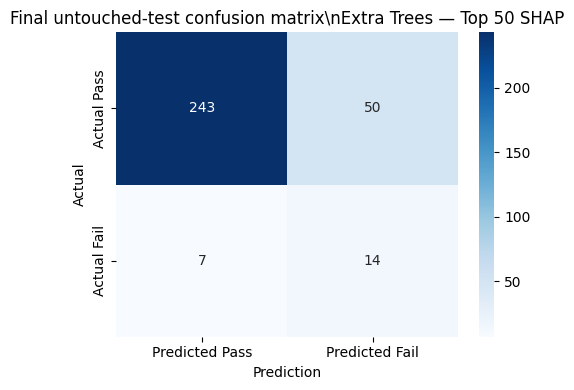

Saved selected trained model: secom_selected_shap_model.joblib


In [14]:
# 6B. EVALUATE ONLY THE SELECTED CONFIGURATION ON THE UNTOUCHED TEST SET
#
# The winning model/subset and threshold were chosen using training-only OOF predictions.
# We evaluate that one selected configuration on the test set exactly once.

final_model = final_models[(best_model_name, best_subset_label)]
final_selected_features = final_feature_sets[best_subset_label]

print("Final selected model:", best_model_name)
print("Final selected subset:", best_subset_label)
print("Number of features used:", len(final_selected_features))
print("Features used:", final_selected_features)

test_probability = final_model.predict_proba(
    X_test_ready[final_selected_features]
)[:, 1]
test_prediction = (test_probability >= best_threshold).astype(int)

test_result = pd.DataFrame([metrics_at_threshold(
    y_test, test_probability, best_threshold,
    model_name=best_model_name, subset=best_subset_label
)])
display(test_result[[
    "model", "feature_subset", "threshold", "balanced_accuracy", "roc_auc",
    "pr_auc_average_precision", "recall", "precision", "f1", "f2",
    "TN", "FP_false_alarms", "FN_missed_failures", "TP"
]].round(4))

cm = confusion_matrix(y_test, test_prediction, labels=[0, 1])
plt.figure(figsize=(5, 4))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
            xticklabels=["Predicted Pass", "Predicted Fail"],
            yticklabels=["Actual Pass", "Actual Fail"])
plt.title(f"Final untouched-test confusion matrix\\n{best_model_name} — {best_subset_label}")
plt.xlabel("Prediction")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

# Optional: save the selected trained model and its exact feature list.
import joblib
joblib.dump(
    {
        "model": final_model,
        "selected_features": final_selected_features,
        "threshold": best_threshold,
        "model_name": best_model_name,
        "feature_subset": best_subset_label,
        "imputer": final_imputer,
        "statistical_selector": final_selector,
    },
    "secom_selected_shap_model.joblib"
)
print("Saved selected trained model: secom_selected_shap_model.joblib")


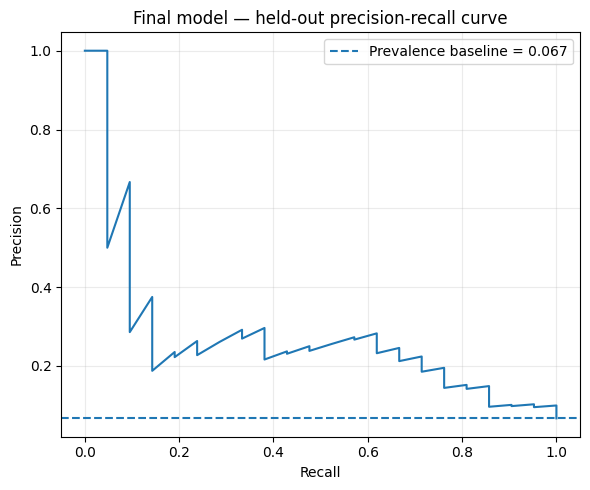

In [15]:
# Precision-recall curve for the one selected final model (test labels used only for final evaluation).
precision_curve, recall_curve, _ = precision_recall_curve(y_test, test_probability)
plt.figure(figsize=(6, 5))
plt.plot(recall_curve, precision_curve)
plt.axhline(y=y_test.mean(), linestyle="--", label=f"Prevalence baseline = {y_test.mean():.3f}")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Final model — held-out precision-recall curve")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

## 7. Save the experiment outputs

The CSV files record the OOF comparison, the training-only final SHAP ranking, and the final selected transformed features. Keep them with the notebook so results can be reviewed and reproduced.

In [16]:
oof_summary.to_csv("secom_shap_subset_oof_comparison.csv", index=False)
final_shap_importance.to_csv("secom_shap_importance_training_only.csv", index=False)
pd.DataFrame({"selected_feature": final_selected_features}).to_csv(
    "secom_final_selected_features.csv", index=False
)
test_result.to_csv("secom_shap_feature_selection_final_test_result.csv", index=False)
fold_shap_long.to_csv("secom_foldwise_shap_importance.csv", index=False)

print("Saved:")
print(" - secom_shap_subset_oof_comparison.csv")
print(" - secom_shap_importance_training_only.csv")
print(" - secom_final_selected_features.csv")
print(" - secom_shap_feature_selection_final_test_result.csv")
print(" - secom_foldwise_shap_importance.csv")

Saved:
 - secom_shap_subset_oof_comparison.csv
 - secom_shap_importance_training_only.csv
 - secom_final_selected_features.csv
 - secom_shap_feature_selection_final_test_result.csv
 - secom_foldwise_shap_importance.csv


## 8. How to interpret the result

- **Primary comparison:** OOF F2/recall at the per-configuration threshold selected from OOF predictions.
- **Ranking quality:** Average Precision (`pr_auc_average_precision`) and ROC-AUC are threshold-independent summaries.
- **Operational burden:** `FP_false_alarms` and `FN_missed_failures` quantify false alarms and missed failures on the final test set.
- **Stability:** use `secom_foldwise_shap_importance.csv` to see which features repeatedly rank highly across folds.
- **No guaranteed improvement:** a smaller SHAP-ranked subset may improve or hurt performance; choose based on OOF evidence and verify once on the untouched test set.
- **Interpretation, not causality:** feature names are anonymized and SHAP describes the model's learned behavior, not physical root cause.

Because this dataset has only 104 failures in total, each fold and the final test set contain few positive examples. Recall may move substantially when one or two failure predictions change. Report counts and uncertainty, not just a percentage.